In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import numpy as np
import pandas as pd
from utils.MyTools import MyTools
from sklearn.datasets import load_iris


# ---------- 测试 ----------
# if __name__ == '__main__':
#     np.random.seed(0)
#     pts = np.random.uniform(-3, 3, (20, 2))
#     idx1 = {0:[0,1,3,4,5],1:[6,7,8,9,10],2:[11,12,13,14,15],3:[0,12,16,17,18,19],4:[0]}
#     MyTools.myPlotPointPairs(pts, idx1,single='N')

In [2]:
#修正后整体代码
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import numpy as np

In [19]:
iris = load_iris()
data = iris.data
data2 = data -  np.mean(data,axis=0)

In [4]:
# 绕 Z 轴旋转点 (1,0,0) 90 度，得到 (0,1,0)
result = myVRotation3D([0,0,1], [1,0,0])
print(result)  # [0. 1. 0.]

# 任意轴
axis = [1,1,1]
point = [1,0,0]
angle = np.radians(60)  # 60度
rotated = myVectorRotation(axis, point, angle)
print(rotated)

[6.123234e-17 1.000000e+00 0.000000e+00]
[ 0.66666667  0.66666667 -0.33333333]


In [2]:
np.random.random(10)

array([0.529407  , 0.3136897 , 0.17553272, 0.79294433, 0.71486942,
       0.44476618, 0.86770718, 0.06536275, 0.97726207, 0.59168268])

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({'col1':np.random.random(6),'col2':np.random.random(6)*2,'col3':np.random.random(6)*3})




In [9]:
type(df.values.squeeze())


numpy.ndarray

In [29]:
data[:,2]@data[:,2]

np.float64(2582.71)

In [30]:
t

array([[2582.71,  869.11],
       [ 869.11,  302.33]])

In [59]:
# 测试SVD中Vt和原数据的关系
#先需要造数据
t = np.linspace(0,2*np.pi,100)
x = 5 + 4*np.sin(t)
y = 2*np.cos(t)
arr1 = np.column_stack((x,y))

tarr = np.array([[np.cos(np.pi/6),-np.sin(np.pi/6)],[np.sin(np.pi/6),np.cos(np.pi/6)]])
S,sigma,Vt = np.linalg.svd(arr1)



In [60]:
arr2 = tarr@arr1.T
arr2 = arr2.T

In [67]:
t = np.column_stack((np.linspace(6.5,8,10),np.linspace(6.5,8,10) + 2))

In [69]:
tarr2 = np.vstack((arr2,t))

In [70]:
S,sigma,Vt = np.linalg.svd(tarr2)

In [71]:
arr3 = arr2@Vt.T

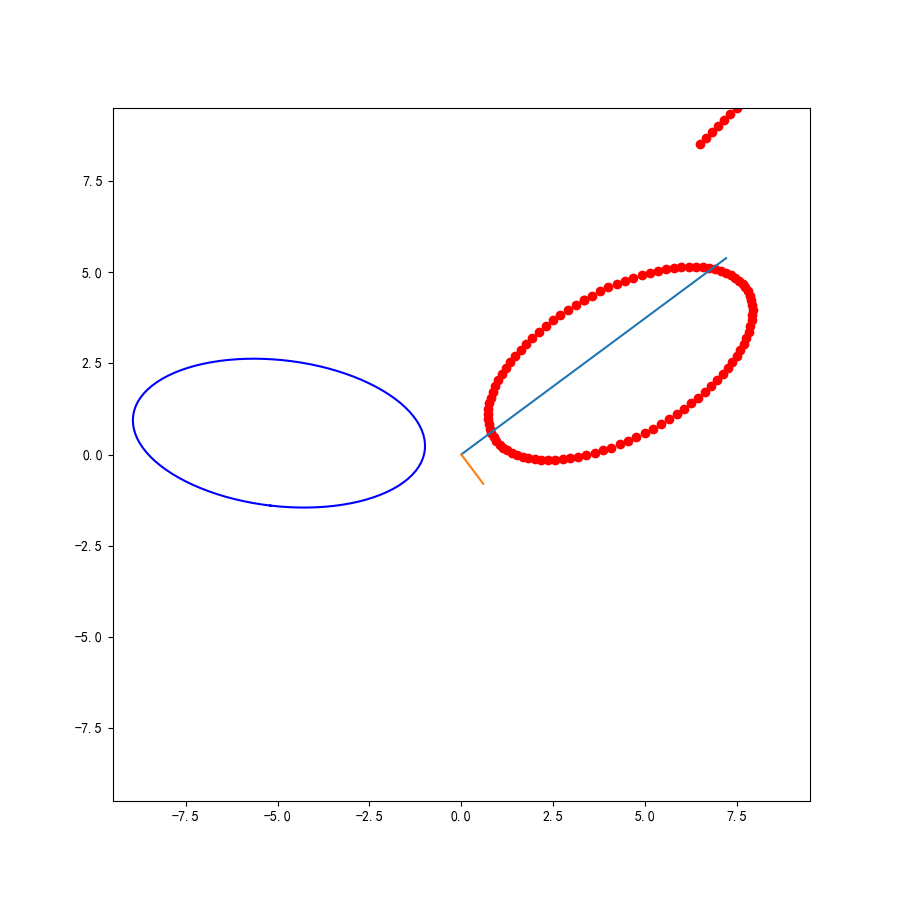

In [72]:

plt.close('all')
fig = plt.figure(figsize=(9,9))
plt.plot(tarr2[:,0],tarr2[:,1],'ro')
plt.plot(arr3[:,0],arr3[:,1],'b-')
plt.plot([0,Vt[0,0]*(-9)],[0,Vt[0,1]*(-9)])
plt.plot([0,Vt[1,0]],[0,Vt[1,1]])
plt.xlim(-9.5,9.5)
plt.ylim(-9.5,9.5)
# plt.set_xlim(-7.5,7.5)
plt.show()



In [44]:
Vt

array([[-0.86440277, -0.50280001],
       [ 0.50280001, -0.86440277]])

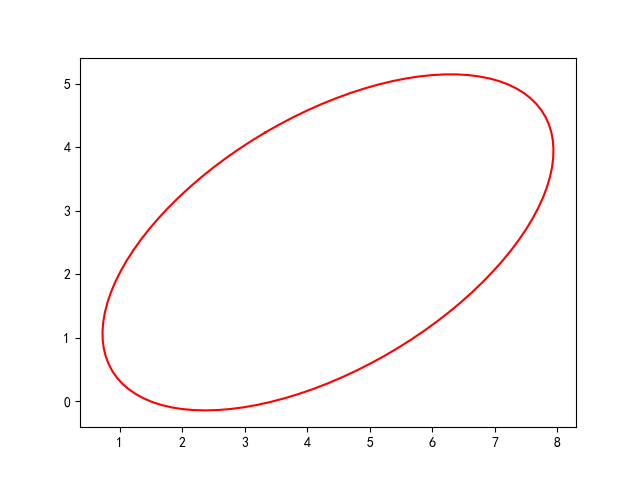

In [18]:
plt.close('all')
plt.plot(arr2[:,0],arr2[:,1],'r-')
plt.show()

In [25]:
arr2 = arr1@(Vt.T)

In [27]:
arr2[:,0]@arr2[:,1]

np.float64(-1338.0372752655276)

In [26]:
plt.plot(arr2[:,0],arr2[:,1],'r-')

In [16]:
np.hstack((iris.feature_names,['target']))

array(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'], dtype='<U17')

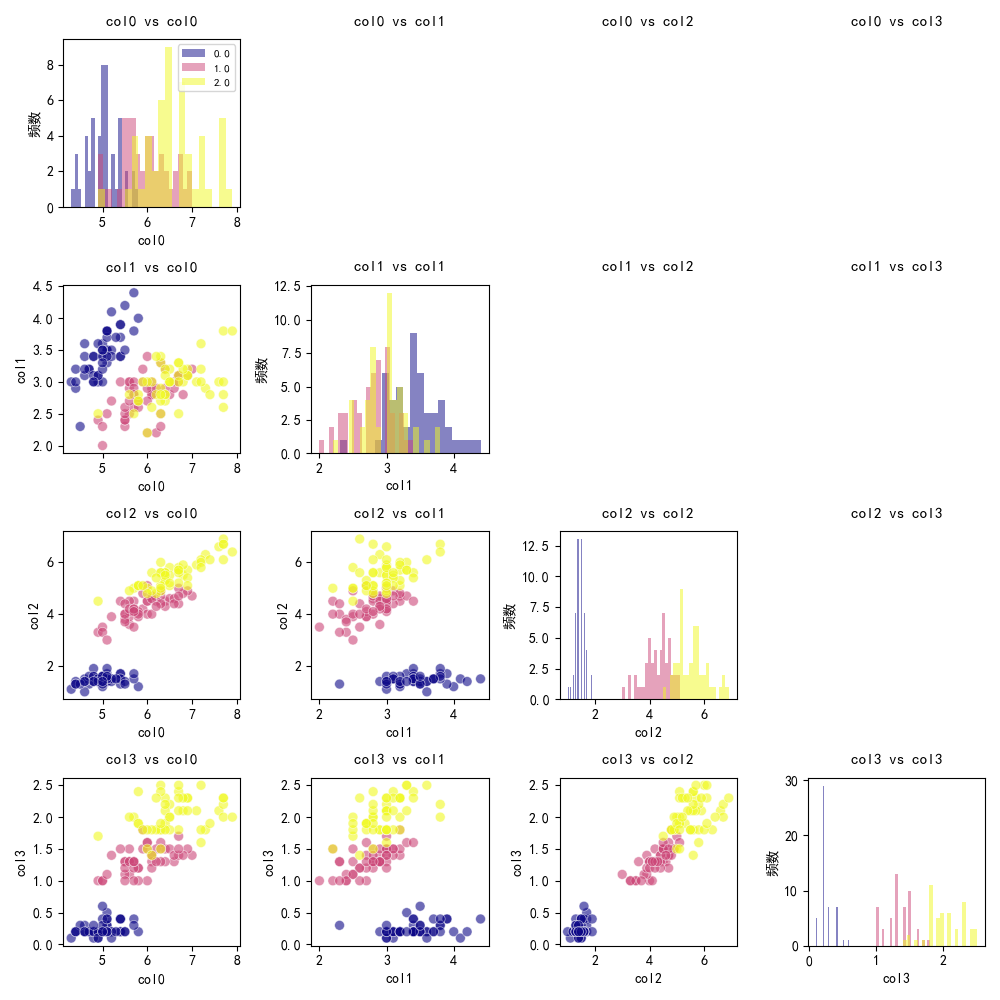

In [24]:
# 对栾尾花的数据两两绘图，观察有用的维度
from utils.MyTools import MyTools

#先获取栾尾花数据：

df = pd.DataFrame(arr,columns=np.hstack(([f'col{i}' for i in range(4)],['target'])) )
fig,ax = MyTools.myPltNumNum(df,[f'col{i}' for i in range(4)],mdl='target',figsize=(10,10))




In [25]:
df

,col0,col1,col2,col3,target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0


In [2]:
#计算第0，和第1列的熵。

def entropy_continuous(values, bins=30):
    """将连续值分箱后计算熵"""
    hist, _ = np.histogram(values, bins=bins)
    probs = hist / hist.sum()
    probs = probs[probs > 0]   # 去掉零概率
    return -np.sum(probs * np.log2(probs))

# 示例
vals = np.random.randn(1000)
print(entropy_continuous(vals, bins=20))

In [1]:
from utils.DecisionTree import DTree

In [36]:
import numpy as np
import pandas as pd
import warnings

def entropy(series, base=2):
    """计算边缘熵 H(series)"""
    probs = series.value_counts(normalize=True)
    return -np.sum(probs * np.log(probs) / np.log(base)) #np.log是以e为底，为了以2为底，所以只是进行了换底

def joint_entropy(series1, series2, base=2):
    """计算联合熵 H(series1, series2)"""
    joint = pd.Series(list(zip(series1, series2)))
    probs = joint.value_counts(normalize=True)
    return -np.sum(probs * np.log(probs) / np.log(base))

def conditional_entropy(target, feature, base=2):
    """计算条件熵 H(target | feature) = H(target, feature) - H(feature)"""
    return joint_entropy(target, feature, base) - entropy(feature, base)

def feature_entropy_analysis(df, target_col, bins=10, base=2, numeric_bins='auto'):
    """
    分析每个特征相对于目标列的信息量。
    
    参数
    ----------
    df : DataFrame
        输入数据。
    target_col : str
        目标列（类别标签）。
    bins : int, 默认 10
        数值特征分箱数量。
    base : float, 默认 2
        对数底。
    numeric_bins : 'auto' 或 int
        如果 'auto'，则对数值特征先判断唯一值数量，若 > bins 则分箱。
    
    返回
    -------
    DataFrame : 
        包含每个特征（不包括目标）的：
        - 边缘熵 H(feature)
        - 联合熵 H(feature, target)
        - 条件熵 H(feature | target)
        - 信息增益 IG = H(target) - H(feature | target)
        按信息增益降序排列（即越重要越靠前）。
    """
    target_series = df[target_col]
    H_target = entropy(target_series, base)
    
    results = []
    for col in df.columns:
        if col == target_col:
            continue
        feat = df[col]
        # 处理数值特征
        if pd.api.types.is_numeric_dtype(feat) and feat.nunique() > bins:
            if numeric_bins == 'auto':
                # 自适应：如果唯一值数量 > bins，则分箱
                feat_binned = pd.cut(feat, bins=bins, labels=False, include_lowest=True).fillna(-1).astype(int)
            else:
                feat_binned = feat
        else:
            feat_binned = feat
        
        # 计算各项指标
        # print(feat_binned)
        H_f = entropy(feat_binned, base)
        H_joint = joint_entropy(feat_binned, target_series, base)
        H_c = H_joint - H_f  # H(feature | target) = H(feature,target) - H(target)
        # 注意：条件熵也可以直接用 conditional_entropy(feat_binned, target_series) 但需要先计算 H(target)
        # 这里使用联合熵减边缘熵 H(feature) 来算，更稳定。
        # 但信息增益 = H(target) - H(target | feature)  ≠ H(target) - H(feature | target)
        # 正确公式：IG = H(target) - H(target | feature)
        # 而 H(target | feature) = H(target, feature) - H(feature)
        # 所以 IG = H(target) - (H_joint - H_f)
        IG = H_target - (H_joint - H_f)
        
        results.append({
            'feature': col,
            'H(feature)': H_f,
            'H(feature,target)': H_joint,
            'H(feature|target)': H_c,
            'Information Gain': IG
        })
    
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('Information Gain', ascending=False).reset_index(drop=True)
    return result_df

def select_features_stepwise(df, target_col, max_features=None, bins=10, base=2):
    """
    使用贪心前向选择（逐步选择）特征。
    
    每次选择当前信息增益最高的特征，并可以继续添加更多特征（但注意冗余问题）。
    如果 max_features 为 None，则返回所有特征按重要性排序的列表。
    若指定数量，则返回前 max_features 个。
    """
    analysis = feature_entropy_analysis(df, target_col, bins, base)
    selected = analysis['feature'].tolist()
    if max_features is not None:
        selected = selected[:max_features]
    return selected

In [37]:
from sklearn.datasets import load_iris
import pandas as pd

# 加载数据
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target   # 目标列，值为 0,1,2

# 1. 分析所有特征
analysis_df = feature_entropy_analysis(df, target_col='species', bins=10)
print(analysis_df)

# 2. 按信息增益排序的特征名（最重要的排前面）
best_features = analysis_df['feature'].tolist()
print("特征重要性排序:", best_features)

# 3. 逐步选择前2个特征
selected = select_features_stepwise(df, target_col='species', max_features=2)
print("选出的前2个特征:", selected)

             feature  H(feature)  H(feature,target)  H(feature|target)  Information Gain
0   petal width (cm)    2.939670           3.097277           0.157607          1.427356
1  petal length (cm)    2.845983           3.079918           0.233934          1.351028
2  sepal length (cm)    3.118885           3.973944           0.855059          0.729904
3   sepal width (cm)    2.773335           3.917515           1.144180          0.440782
特征重要性排序: ['petal width (cm)', 'petal length (cm)', 'sepal length (cm)', 'sepal width (cm)']
选出的前2个特征: ['petal width (cm)', 'petal length (cm)']


In [79]:
from sklearn.datasets import load_iris
from sklearn.feature_selection import mutual_info_classif
import pandas as pd
import numpy as np

# 加载数据
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

from sklearn.feature_selection import mutual_info_classif
import pandas as pd
import numpy as np
def calcMutual(df,col=None):
    rst = dict()
    if isinstance(df,pd.DataFrame):
        if col is None:
            X = df.iloc[:,:-1]
            y = df.iloc[:,-1]
        else:
            X = df[[i for i in df.columns if i != col ]]
            y = df[col]
        mi = mutual_info_classif(X, y, random_state=42)
        for i,v in enumerate(X.columns):
            rst[v] = mi[i]
    else:
        if col is None:
            X = df[:,:-1]
            y = df[:,-1]
        else:
            X = df[:,[i for i in range(df.shape[1]) if i != col ]]
            y = df[:,col]
        mi = mutual_info_classif(X, y, random_state=42)
        for i,v in enumerate(mi):
            rst[f'col{i}'] = v
    return rst


In [80]:
calcMutual(df.values,4)

{'col0': np.float64(0.5113651047986985),
 'col1': np.float64(0.2994243107086385),
 'col2': np.float64(0.9925730881120935),
 'col3': np.float64(0.9856425060576723)}

In [67]:
for i,v in enumerate(df.columns):
    print(i,v)

0 sepal length (cm)
1 sepal width (cm)
2 petal length (cm)
3 petal width (cm)
4 species


In [74]:
[i for i in range(df.values.shape[1]) if i != 4 ]

[0, 1, 2, 3]

In [33]:
conditional_entropy(df['species'],df['sepal length (cm)'])

np.float64(0.7080248798300985)

In [32]:
df.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='object')

In [27]:
pe = torch.zeros(1024, 512)
pe1 = torch.zeros(1024, 512)
position = torch.arange(0, 1024, dtype=torch.float).unsqueeze(1)
div_term = torch.exp(torch.arange(0, 512, 2).float() * 
                   (-math.log(10000.0) / 512))

pe1[:, 0::2] = position * div_term
pe1[:, 1::2] = position * div_term
pe[:, 0::2] = torch.sin(position * div_term)
pe[:, 1::2] = torch.cos(position * div_term)

# pe = pe.unsqueeze(0).transpose(0, 1)

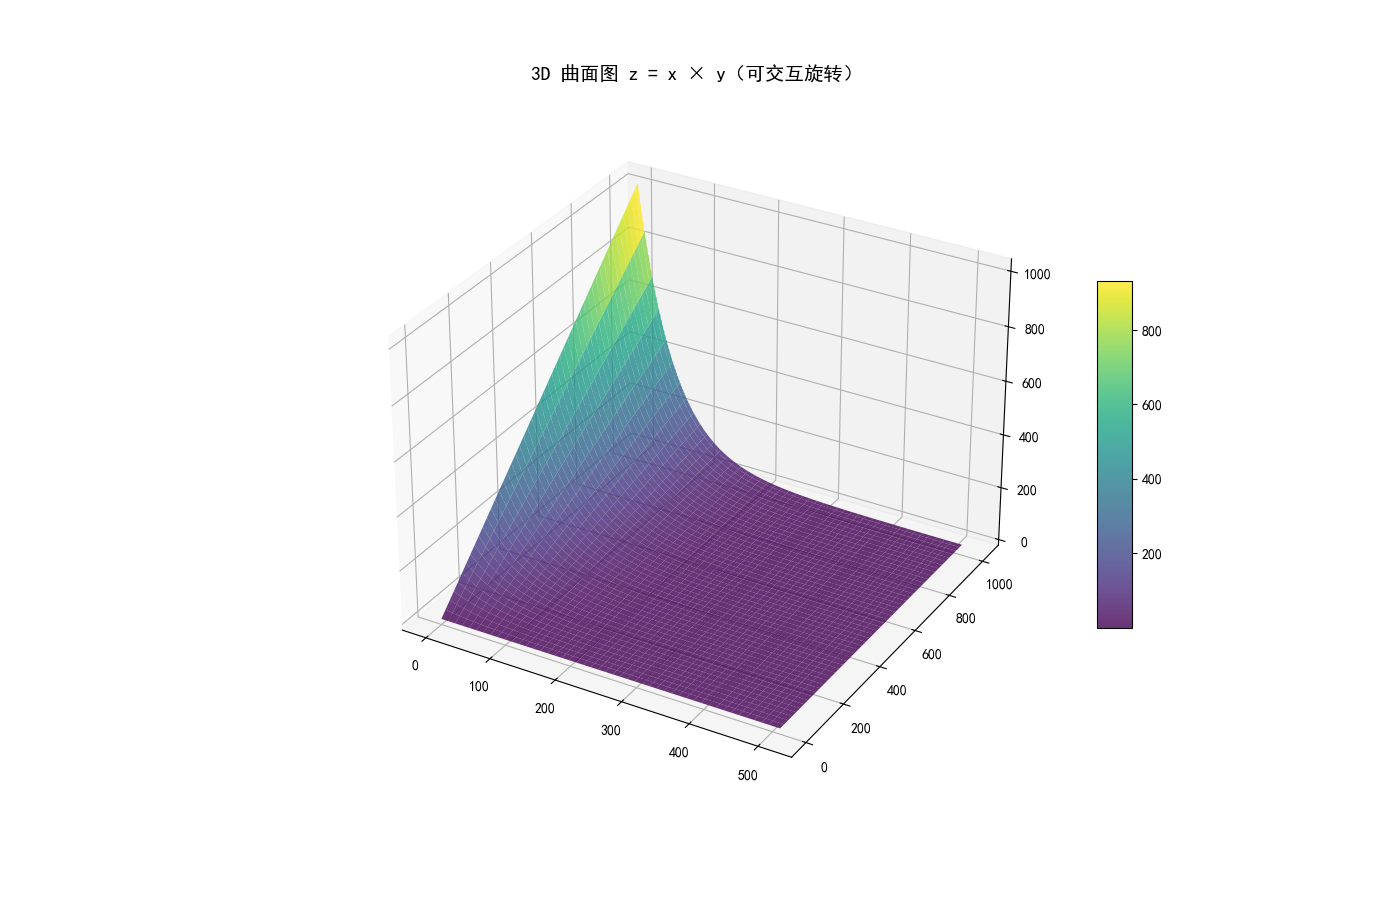

In [30]:
%matplotlib widget
from utils.MyTools import MyTools
_ = MyTools.myPlot3d(data=pe1,p='N')

In [ ]:
%matplotlib widget
from utils.MyTools import MyTools
a = pe[:, 0::2]
_ = MyTools.myPlot3d(data=pe[:,0::2],col_slice="50,52",p='Y')



In [1]:
#找出没有实数特征向量的矩阵
import numpy as np
a1 = np.linspace(-3,3,50)
a2 = np.linspace(-3,3,50)
a11,a22 = np.meshgrid(a1,a2)
a11 = a11.ravel()
a22 = a22.ravel()
A1 =  np.concat((a11[:,None],a22[:,None]),axis=1)
ai = []
aj = []
for i in range(len(A1)):
    for j in range(len(A1)):
        if i != j:
            _1,_2 = np.linalg.eig(np.column_stack((A1[i,:],A1[j,:]) ) )
            if np.iscomplex(_1).any():
                ai.append(i)
                aj.append(j)

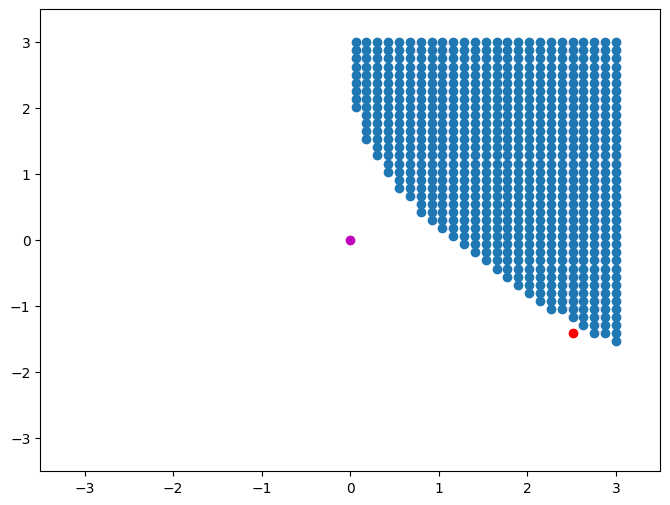

In [22]:
import matplotlib.pyplot as plt
# from matplotlib.animation import FuncAnimation
import numpy as np

ai = np.array(ai)
aj = np.array(aj)

i = 695
A = A1[aj[ai==i]]

plt.close('all')
fig,ax = plt.subplots(figsize=(8,6))
ax.set_xlim(-3.5,3.5)
ax.set_ylim(-3.5,3.5)

sc = ax.scatter([0],[0],c='m')
sc = ax.scatter([A1[i,0]],[A1[i,1]],c='r')
sc = ax.scatter(A[:,0],A[:,1])

In [2]:
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'DejaVu Sans', 'Arial', 'Liberation Sans', 'Noto Sans CJK SC']
plt.rcParams['axes.unicode_minus'] = False

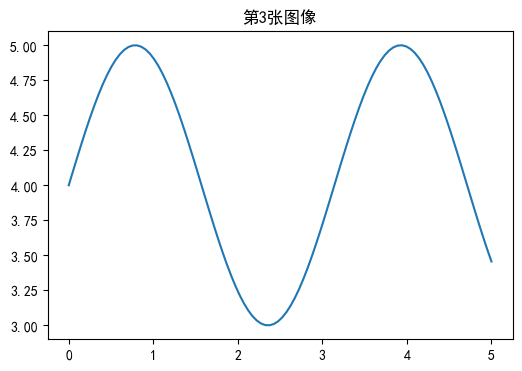

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output
import time

fig, ax = plt.subplots(figsize=(6,4))
plt.close(fig) # 关闭初始空白图

for i in range(3):
    fig, ax = plt.subplots(figsize=(6,4))
    x = np.linspace(0,5,100)
    y = np.sin(i*x) + i*2
    ax.plot(x,y)
    ax.set_title(f'第{i+1}张图像')
    plt.show()
    time.sleep(1)
    clear_output(wait=True)

In [ ]:
np.linspace(0,)

In [1]:
from utils.MyTools import MyTools
import numpy as np

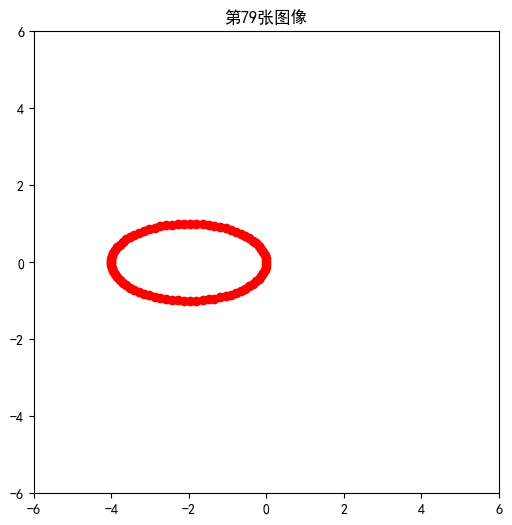

In [2]:
arr1 = np.linspace(0,np.pi * 2 ,80)
x = 2*np.cos(arr1) + 2
y = np.sin(arr1)
MyTools.myPltGradient(np.column_stack((x,y)),xlim=(-6,6),ylim=(-6,6))

In [2]:
from sklearn.datasets import load_iris

In [3]:
iris = load_iris()

In [4]:
data = iris.data

In [6]:
U,S,Vt = np.linalg.svd(data.T)

In [7]:
U

array([[-0.75110816, -0.2841749 ,  0.50215472,  0.32081425],
       [-0.38008617, -0.5467445 , -0.67524332, -0.31725607],
       [-0.51300886,  0.70866455, -0.05916621, -0.48074507],
       [-0.16790754,  0.34367081, -0.53701625,  0.75187165]])